# 1. Exploration des données

Jeu de données : transactions par carte bancaire du simulateur Sparkov (Kaggle, licence CC0), fichiers `fraudTrain.csv` et `fraudTest.csv` rassemblés puis triés par date.
Ce carnet décrit la cible, les montants et la structure temporelle de la fraude avant toute modélisation.

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().resolve().parent
if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message="IProgress not found")
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 30
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

BLEU = "#2a78d6"
ORANGE = "#eb6834"
VERT = "#1baf7a"
JAUNE = "#eda100"
ROSE = "#e87ba4"

In [2]:
from src import donnees, exploration

df = donnees.charger()
df.shape

(1852394, 21)

In [3]:
df.dtypes

trans_date_trans_time    datetime64[us]
cc_num                            int64
merchant                            str
category                            str
amt                             float64
first                               str
last                                str
gender                              str
street                              str
city                                str
state                               str
zip                               int64
lat                             float64
long                            float64
city_pop                          int64
job                                 str
dob                                 str
trans_num                           str
merch_lat                       float64
merch_long                      float64
is_fraud                          int64
dtype: object

In [4]:
df.head(3).T

,0,1,2
trans_date_trans_time,2019-01-01 00:00:18,2019-01-01 00:00:44,2019-01-01 00:00:51
cc_num,2703186189652095,630423337322,38859492057661
merchant,"fraud_Rippin, Kub and Mann","fraud_Heller, Gutmann and Zieme",fraud_Lind-Buckridge
category,misc_net,grocery_pos,entertainment
amt,4.9700,107.2300,220.1100
first,Jennifer,Stephanie,Edward
last,Banks,Gill,Sanchez
gender,F,F,M
street,561 Perry Cove,43039 Riley Greens Suite 393,594 White Dale Suite 530
city,Moravian Falls,Orient,Malad City


## Qualité de base

In [5]:
pd.DataFrame({
    "valeurs_manquantes": df.isna().sum(),
    "valeurs_distinctes": df.nunique(),
}).T

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,merch_lat,merch_long,is_fraud
valeurs_manquantes,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
valeurs_distinctes,1819551,999,693,14,60616,355,486,2,999,906,51,985,983,983,891,497,984,1852394,1754157,1809753,2


In [6]:
{
    "periode": (df["trans_date_trans_time"].min(), df["trans_date_trans_time"].max()),
    "cartes": df["cc_num"].nunique(),
    "identifiants_de_transaction_dupliques": int(df["trans_num"].duplicated().sum()),
    "lignes_dupliquees": int(df.duplicated().sum()),
}

{'periode': (Timestamp('2019-01-01 00:00:18'),
  Timestamp('2020-12-31 23:59:34')),
 'cartes': 999,
 'identifiants_de_transaction_dupliques': 0,
 'lignes_dupliquees': 0}

## Taux de fraude et montants

In [7]:
exploration.resume_global(df).T

,0
transactions,"1,852,394.0000"
fraudes,"9,651.0000"
taux_fraude,0.0052
montant_total,"129,785,332.0100"
montant_fraudes,"5,121,413.2900"
part_montant_fraudes,0.0395


In [8]:
exploration.montants_par_classe(df)

,transactions,moyenne,mediane,ecart_type,minimum,q1,q3,maximum
is_fraud,,,,,,,,
0,1842743,67.6513,47.2400,153.5481,1.0000,9.6100,82.5600,"28,948.9000"
1,9651,530.6614,390.0000,391.0289,1.0600,240.0750,902.3650,"1,376.0400"


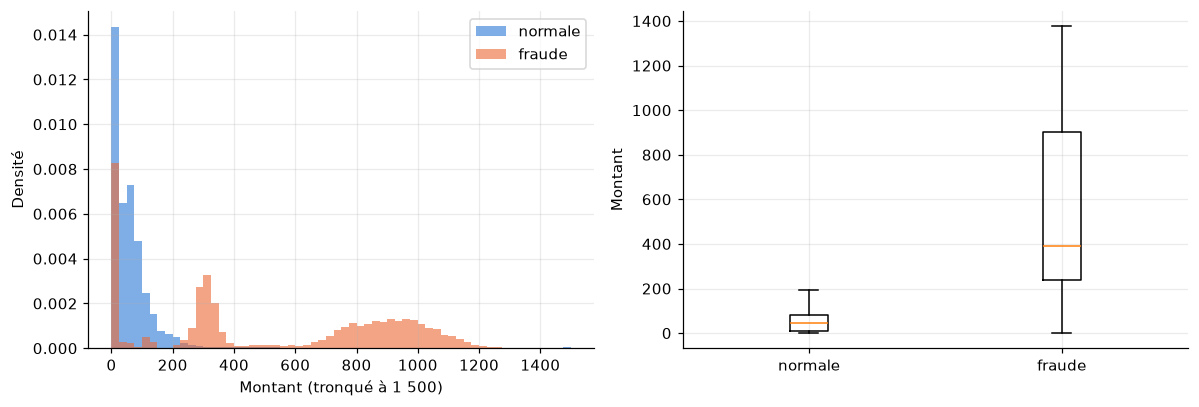

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
bornes = np.linspace(0, 1500, 61)
for classe, couleur, nom in ((0, BLEU, "normale"), (1, ORANGE, "fraude")):
    montants = df.loc[df["is_fraud"] == classe, "amt"].clip(upper=1500)
    axes[0].hist(montants, bins=bornes, color=couleur, alpha=0.6, density=True, label=nom)
axes[0].set_xlabel("Montant (tronqué à 1 500)")
axes[0].set_ylabel("Densité")
axes[0].legend()
axes[1].boxplot([df.loc[df["is_fraud"] == c, "amt"] for c in (0, 1)], tick_labels=["normale", "fraude"], showfliers=False)
axes[1].set_ylabel("Montant")
fig.tight_layout()

In [10]:
fraudes = df.loc[df["is_fraud"] == 1, "amt"]
fraudes.describe(percentiles=[0.01, 0.5, 0.99]).to_frame("fraudes")

,fraudes
count,"9,651.0000"
mean,530.6614
std,391.0289
min,1.0600
1%,6.8400
50%,390.0000
99%,"1,175.8500"
max,"1,376.0400"


## Évolution dans le temps

,transactions,taux_fraude
min,"47,791.0000",0.0018
mean,"77,183.0833",0.0056
max,"141,060.0000",0.0104


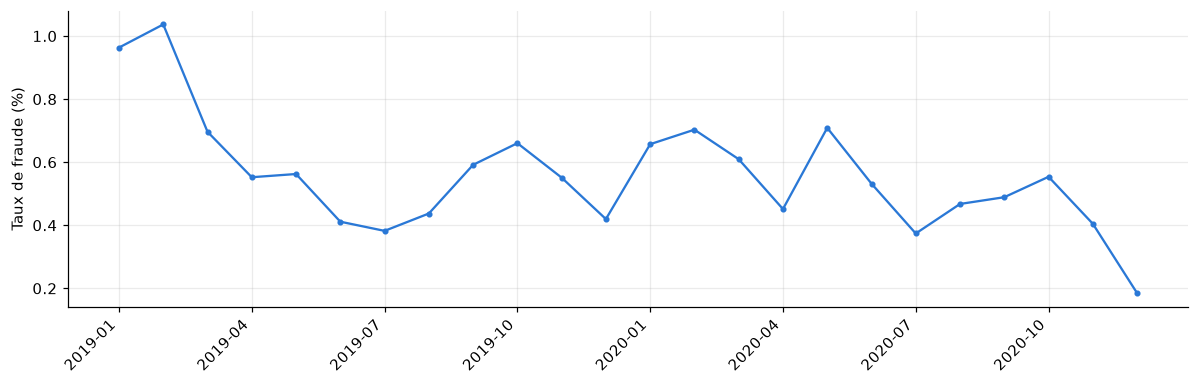

In [11]:
par_mois = exploration.taux_par_mois(df)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(par_mois.index, par_mois["taux_fraude"] * 100, color=BLEU, marker="o", markersize=3)
ax.set_ylabel("Taux de fraude (%)")
ax.set_xticks(range(0, len(par_mois), 3))
ax.set_xticklabels(par_mois.index[::3], rotation=45, ha="right")
fig.tight_layout()
par_mois.describe().loc[["min", "mean", "max"], ["transactions", "taux_fraude"]]

## Heure, jour et catégorie

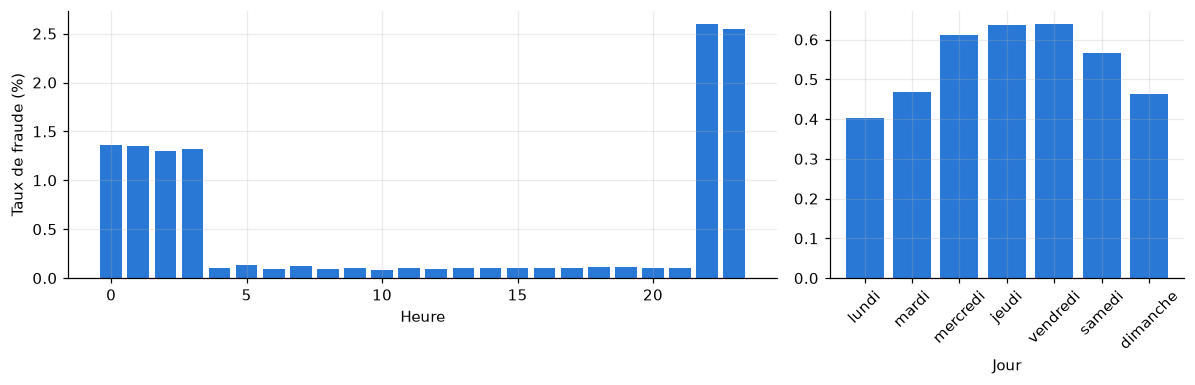

In [12]:
par_heure = exploration.taux_par_heure(df)
par_jour = exploration.taux_par_jour_semaine(df)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [2, 1]})
axes[0].bar(par_heure.index, par_heure["taux_fraude"] * 100, color=BLEU)
axes[0].set_xlabel("Heure")
axes[0].set_ylabel("Taux de fraude (%)")
axes[1].bar(par_jour.index, par_jour["taux_fraude"] * 100, color=BLEU)
axes[1].set_xlabel("Jour")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()

,transactions,fraudes,taux_fraude,montant_fraudes
categorie,,,,
shopping_net,139322,2219,0.0159,"2,214,847.6400"
misc_net,90654,1182,0.0130,"944,009.7100"
grocery_pos,176191,2228,0.0126,"695,664.6200"
shopping_pos,166463,1056,0.0063,"928,132.3400"
gas_transport,188029,772,0.0041,"9,442.5300"
misc_pos,114229,322,0.0028,"68,494.8400"
grocery_net,64878,175,0.0027,"2,108.2100"
travel,57956,156,0.0027,"1,399.4700"
personal_care,130085,290,0.0022,"7,571.9600"


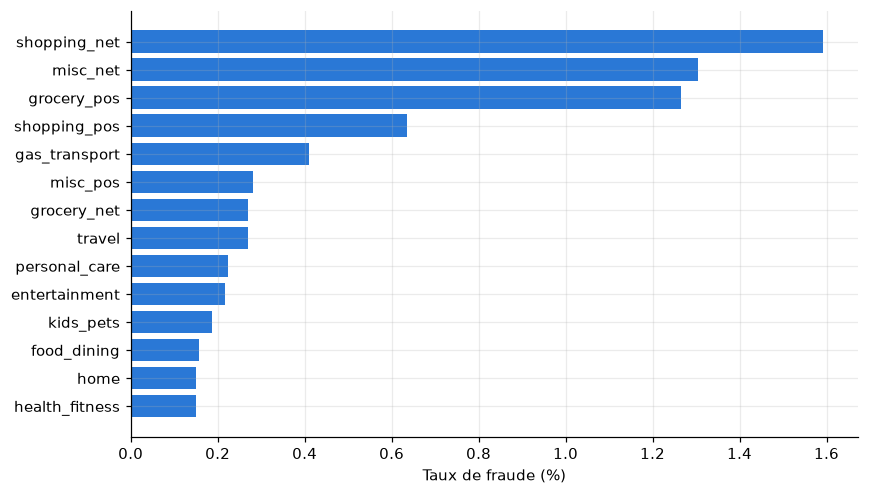

In [13]:
par_categorie = exploration.taux_par_categorie(df)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(par_categorie.index[::-1], par_categorie["taux_fraude"].iloc[::-1] * 100, color=BLEU)
ax.set_xlabel("Taux de fraude (%)")
fig.tight_layout()
par_categorie

In [14]:
exploration.taux_par_canal(df)

,transactions,fraudes,taux_fraude,montant_fraudes
canal,,,,
en ligne,294854,3576,0.0121,"3,160,965.5600"
magasin,456883,3606,0.0079,"1,692,291.8000"
non precise,1100657,2469,0.0022,"268,155.9300"


## Lecture

- La fraude est rare (de l'ordre de 0,5 % des transactions) : l'exactitude n'est pas une métrique pertinente et le déséquilibre doit être traité.
- Les montants des fraudes sont nettement plus élevés que ceux des transactions normales et suivent une distribution propre à chaque catégorie.
- Le taux de fraude est concentré la nuit, ce qui justifie des variables d'heure à codage cyclique.
- Le simulateur ne fournit pas de canal explicite : il est déduit du suffixe de la catégorie (`_pos` en magasin, `_net` en ligne).